# Midline fitting: slice spline vs mask-Denis 8 vs Denis (recording 2024-02-20T12_32_58)

**Approaches** (code: `midline_methods.py`, per-frame runner: `midline_fit_runner.py`)

| name | uses | how |
|---|---|---|
| **slice spline** | mask | every pixel gets its distance *through the body* from one body tip; the centroids of 1-px slices of that distance (one per px of body length) are fitted by **one penalised spline**: 40 knots, penalty λ = 10 on third differences (changes in bending), ends pinned |
| **mask-Denis 8** | mask | 8 points: the two body tips + 6 slice centroids evenly spaced between them → Denis's interpolation |
| **Denis (4 SLEAP)** | SLEAP | Denis's method (EODAssignment) on the tracked tail, middle, head, mouth |

**Data:** efish4-track (Kaden) visible masks, raw (fins kept), of every video frame (30,845 frames × 4 fish); SLEAP keypoints
from `Data_4fish_2024-02-20T12_32_58_no_ref_per.csv` (frames with an EOD; mask frame = CSV `Frame`). Denis is drawn only on
frames that have a SLEAP row whose middle and head keypoints lie on the mask (within 10 px summed).

**Head end of the mask-based midlines:** the wider end of the body (more mask area in its third), and during contact
(Kaden's `occluded` flag) continuity with the nearest contact-free frames (`Midline_five_way_12_32_58.ipynb` §4c). This agrees with SLEAP in 99.95 % of masks.

**Metrics** (all per mask, in px of the 912 × 912 video)

| metric | meaning | better |
|---|---|---|
| % inside | share of the 200 midline points inside the mask | high |
| interior % inside | the same without the 10 points at each end (ends legitimately touch the mask edge) | high |
| px outside | furthest midline point outside the mask | low |
| wiggle | RMS distance between the midline and a much smoother version of itself (order-3 penalty, λ = 1000): small-scale jiggle *along the body* | low |
| total turning | sum of absolute direction changes along the midline (a straight fish ≈ 0°, a C-bend ≈ its bend) | realistic |
| jitter | frame-to-frame: mean over the 200 points of \|p(t+1) − 2p(t) + p(t−1)\|, the second difference in time; 0 for steady swimming, large for flicker | low |
| head flips | head end moving > 25 px between consecutive frames (head/tail swap or big jump), per 1000 frame steps | low |

In [1]:
import os, pickle, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates, distance_transform_edt
import midline_methods as mm
import midline_fit_runner as fr
import synthetic_fish as sf

RUN_DIR   = 'data/track_Kaden/results_12_32_58_full/video2024-02-20T12_32_58/outputs'
PKL_PATH  = f'{RUN_DIR}/video2024-02-20T12_32_58.pkl'
CSV_PATH  = 'data/Denis Assignment/Data_4fish_2024-02-20T12_32_58_no_ref_per.csv'
HEAD_CACHE = 'results/head_continuity_12_32_58_mask_visible.csv.gz'
TUNE_CACHE = 'results/slice_spline_tuning_12_32_58.csv.gz'
RUN_CACHE  = 'results/midline_fit_12_32_58_mask_visible.csv.gz'
FIG_DIR    = 'figures/midline_fitting_12_32_58'
RECOMPUTE  = False          # True: redo the tuning (~5 min) and the full run (~17 min on 8 processes)
PROCESSES  = 8

K = pickle.load(open(PKL_PATH, 'rb')); LETTERS = K['letters']; P = K['image_size'][0]
csv = pd.read_csv(CSV_PATH, low_memory=False).groupby('Frame').first()
H = pd.read_csv(HEAD_CACHE); CONT = {(int(f), L): bool(v) for f, L, v in zip(H.frame, H.fish, H.cont_head_is_a)}
def sleap_kp(F, L):
    return np.array([[csv.at[F, f'{p}_y_{L}'], csv.at[F, f'{p}_x_{L}']] for p in fr.PARTS], float) if F in csv.index else None
def kaden_mask(F, i):
    rle = K['mask_visible'][F][i]; return np.zeros((P, P), bool) if rle is None else mm.rle_decode(rle)

AP = list(fr.APPROACHES); NAME = fr.APPROACHES
COLOR = {'slice': '#2a78d6', 'md8': '#eb6834', 'denis': '#1baf7a'}       # blue, orange, aqua (validated palette)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True})
print(f"{K['n_frames']} video frames x {len(LETTERS)} fish; SLEAP rows on {len(csv)} frames")

30845 video frames x 4 fish; SLEAP rows on 16518 frames


## 1. One penalised spline instead of two fitting steps

Variant B fitted the slice centroids in two steps (a least-squares spline with 10 knots, then a penalised spline). Here a
**single penalised spline** is fitted directly to the slice centroids, and its two settings (number of knots, penalty
strength λ) are swept against variant B on:
* **synthetic fish** with a known midline (11 bends × 6 rotations, without and with realistic pectoral fins):
  error vs the true midline and extra total turning vs the true bend (wiggle → positive, flattened bends → negative);
* **800 random real masks**: interior % inside, masks > 1 px outside, total turning, distance from variant B.

In [2]:
def dist_to_poly(p, poly): return np.min(np.linalg.norm(poly[None] - p[:, None], axis=2), axis=1)
SETTINGS = [(k, l) for k in (20, 40, 60) for l in (0.3, 1, 3, 10, 30, 100)]
def candidates(m, head):
    pix, g, a, b = mm.mask_tips(m); pts = mm.slice_centroids(pix, g)
    out = {'B (two steps)': mm.fish_midline_slices(m, head) * (P - 1)}
    for k, l in SETTINGS:
        out[f'single: {k} knots, lam {l}'] = mm._orient(mm.smooth_midline(pts, lam=l, order=3, n_knots=k, n_out=200), head)
    return out

if os.path.exists(TUNE_CACHE) and not RECOMPUTE:
    T = pd.read_csv(TUNE_CACHE)
else:
    rows = []
    for kind, bend in [('C', 0), ('C', 40), ('C', 90), ('S', 30), ('S', 60), ('C', 150), ('C', 200), ('C', 270), ('C', 320), ('S', 120), ('S', 180)]:
        for th in (0, 30, 73, 140, 220, 300):
            for fins in (False, True):
                mid, m = sf.make_fish(th, bend, kind, fins=sf.FINS if fins else ())
                for v, c in candidates(m, mid[-1]).items():
                    d1 = dist_to_poly(c, mid)
                    rows.append(dict(data='synthetic, fins' if fins else 'synthetic, no fins', variant=v, mean_err=d1.mean(),
                                     max_err=max(d1.max(), dist_to_poly(mid[::5], c).max()), turn_excess=mm.turning_deg(c) - mm.turning_deg(mid[::10])))
    rng = np.random.default_rng(0); n_real = 0
    while n_real < 800:
        F, i = int(rng.integers(K['n_frames'])), int(rng.integers(4))
        m = kaden_mask(F, i)
        if m.sum() < 50: continue
        _, _, info = mm.fish_midline_mask_denis_auto(m, 8); head = info['tip_a'] if info['head_is_a'] else info['tip_b']
        cs = candidates(m, head); B = cs['B (two steps)']; dout = distance_transform_edt(~m)
        for v, c in cs.items():
            ins = map_coordinates(m.astype(float), c.T, order=1) >= .5
            rows.append(dict(data='real', variant=v, interior_inside=ins[10:-10].mean(), out1=map_coordinates(dout, c.T, order=1).max() > 1,
                             turning=mm.turning_deg(c), dist_B=dist_to_poly(c, B).max()))
        n_real += 1
    T = pd.DataFrame(rows); os.makedirs('results', exist_ok=True); T.to_csv(TUNE_CACHE, index=False)

order = ['B (two steps)'] + [f'single: {k} knots, lam {l}' for k, l in SETTINGS]
g = lambda d: T[T.data == d].groupby('variant')
tune = pd.DataFrame({
    'no fins: mean err px': g('synthetic, no fins').mean_err.mean(), 'no fins: extra turning °': g('synthetic, no fins').turn_excess.median(),
    'fins: mean err px': g('synthetic, fins').mean_err.mean(), 'fins: median max err px': g('synthetic, fins').max_err.median(),
    'fins: extra turning °': g('synthetic, fins').turn_excess.median(),
    'real: interior % inside': 100 * g('real').interior_inside.mean(), 'real: masks > 1 px out': g('real').out1.sum(),
    'real: median turning °': g('real').turning.median(), 'real: turning > 180° (masks)': g('real').turning.apply(lambda v: (v > 180).sum()),
    'real: max distance to B, median px': g('real').dist_B.median()}).loc[order]
display(tune.round(2).style.apply(lambda r: ['background-color: #fdebd0' if r.name in ('B (two steps)', 'single: 40 knots, lam 10') else '' for _ in r], axis=1))

,no fins: mean err px,no fins: extra turning °,fins: mean err px,fins: median max err px,fins: extra turning °,real: interior % inside,real: masks > 1 px out,real: median turning °,real: turning > 180° (masks),"real: max distance to B, median px"
variant,,,,,,,,,,
B (two steps),0.300000,0.890000,0.500000,1.770000,1.110000,99.920000,True,39.520000,1,0.000000
"single: 20 knots, lam 0.3",0.320000,3.940000,0.510000,1.640000,1.970000,99.910000,True,44.540000,2,0.250000
"single: 20 knots, lam 1",0.430000,3.150000,0.600000,1.520000,-0.130000,99.910000,True,36.180000,1,0.230000
"single: 20 knots, lam 3",0.630000,0.120000,0.820000,1.560000,-2.500000,99.890000,True,30.510000,0,0.430000
"single: 20 knots, lam 10",1.100000,-6.480000,1.270000,1.980000,-8.750000,99.790000,True,25.600000,0,0.710000
"single: 20 knots, lam 30",1.770000,-20.780000,1.870000,3.110000,-20.760000,99.360000,True,21.440000,0,0.980000
"single: 20 knots, lam 100",2.570000,-19.950000,2.620000,4.080000,-19.410000,97.940000,True,18.160000,0,1.380000
"single: 40 knots, lam 0.3",0.260000,4.780000,0.560000,2.490000,28.350000,99.920000,True,88.600000,23,0.970000
"single: 40 knots, lam 1",0.260000,3.610000,0.520000,1.950000,11.180000,99.920000,True,66.470000,7,0.660000


**Chosen: one penalised spline with 40 knots and λ = 10** (highlighted). It matches variant B everywhere: the same error
on synthetic fish with and without fins (a slightly smaller median max error with fins), extra turning within ±1.5° of the
true bend, the same share inside the body and the same turning on real masks, and it lies within ~0.2 px of variant B.
Fewer knots or a larger λ flatten real bends (negative extra turning, larger errors); more knots or a smaller λ let fins and
ragged edges through as wiggles (positive extra turning, many real masks turning > 180°).

## 2. The three midlines on every video frame

Run in chunks of consecutive frames per fish (`midline_fit_runner.py`), so every frame's neighbours are available for the
frame-to-frame jitter. Cached in `RUN_CACHE`.

In [3]:
if os.path.exists(RUN_CACHE) and not RECOMPUTE:
    R = pd.read_csv(RUN_CACHE, low_memory=False); print(f'loaded {RUN_CACHE}')
elif not RECOMPUTE:
    raise FileNotFoundError(f'{RUN_CACHE} not found: set RECOMPUTE = True (~17 min on {PROCESSES} processes)')
else:
    t0 = time.time()
    R = pd.DataFrame(fr.run(fr.tasks_for(K, csv, CONT, 0, K['n_frames'] - 1, LETTERS), processes=PROCESSES, progress_every=0))
    R.to_csv(RUN_CACHE, index=False); print(f'computed in {(time.time() - t0) / 60:.1f} min')
for k in AP: R[f'{k}_ok'] = R[f'{k}_ok'].fillna(False).astype(bool)
R = R.sort_values(['fish', 'frame']).reset_index(drop=True)
both = R.slice_ok & R.md8_ok; all3 = both & R.denis_ok
print(f'{len(R):,} masks (fish with a mask of >= 50 px); mask-based midlines on {both.sum():,}; '
      f'Denis also available on {all3.sum():,} ({100 * all3.mean():.1f} %) - the frames with a usable SLEAP row')
display(R.groupby('fish').agg(masks=('frame', 'size'), sleap_rows=('sleap_row', 'sum'), denis_available=('denis_ok', 'sum'),
                              head_by_continuity=('head_rule', lambda v: (v == 'continuity').sum())))

loaded results/midline_fit_12_32_58_mask_visible.csv.gz
122,180 masks (fish with a mask of >= 50 px); mask-based midlines on 122,180; Denis also available on 65,248 (53.4 %) - the frames with a usable SLEAP row


,masks,sleap_rows,denis_available,head_by_continuity
fish,,,,
A,30845,16518,16454,7320
B,30845,16518,16487,1142
C,30845,16518,16503,1831
D,29645,15807,15804,5964


## 3. Comparison

**3a. All three on the same masks** (frames with a usable SLEAP row, so Denis exists). Jitter needs the neighbouring frames
too, so for Denis it only exists where three consecutive frames have SLEAP rows; the number of masks behind each jitter
value is listed.

In [4]:
def stats(df, keys):
    out = {}
    for k in keys:
        d = df[df[f'{k}_ok']]; ins = d[f'{k}_inside']; j = d[f'{k}_jitter'].dropna(); hs = d[f'{k}_head_step'].dropna()
        out[NAME[k]] = {
            ('inside the body', 'mean % of midline inside'): 100 * ins.mean(),
            ('inside the body', '% of masks with the whole midline inside'): 100 * (ins >= 1).mean(),
            ('inside the body', 'interior % inside (mean)'): 100 * d[f'{k}_inside_interior'].mean(),
            ('inside the body', '% of masks > 1 px outside somewhere'): 100 * (d[f'{k}_px_out'] > 1).mean(),
            ('inside the body', 'furthest outside: 95th pct px'): d[f'{k}_px_out'].quantile(.95),
            ('smoothness along the body', 'wiggle: median px'): d[f'{k}_wiggle'].median(),
            ('smoothness along the body', 'wiggle: 95th pct px'): d[f'{k}_wiggle'].quantile(.95),
            ('smoothness along the body', 'total turning: median °'): d[f'{k}_turning'].median(),
            ('smoothness along the body', '% of masks turning > 180°'): 100 * (d[f'{k}_turning'] > 180).mean(),
            ('frame to frame', 'jitter: median px'): j.median(),
            ('frame to frame', 'jitter: 95th pct px'): j.quantile(.95),
            ('frame to frame', 'head flips per 1000 frame steps'): 1000 * (hs > fr.FLIP_PX).mean(),
            ('frame to frame', 'masks with jitter values'): len(j),
            ('ends and length', 'head end → SLEAP mouth: median px'): d[f'{k}_head_err'].median(),
            ('ends and length', 'tail end → SLEAP tail: median px'): d[f'{k}_tail_err'].median(),
            ('ends and length', 'length: median px'): d[f'{k}_length'].median(),
            ('', 'masks'): len(d)}
    return pd.DataFrame(out)

t3 = stats(R[all3], AP)
display(t3.round(2))

slice spline (mask)  \
inside the body           mean % of midline inside                                99.71   
                          % of masks with the whole midline inside                80.08   
                          interior % inside (mean)                                99.92   
                          % of masks > 1 px outside somewhere                      4.16   
                          furthest outside: 95th pct px                            0.95   
smoothness along the body wiggle: median px                                        0.58   
                          wiggle: 95th pct px                                      1.71   
                          total turning: median °                                 41.00   
                          % of masks turning > 180°                                0.33   
frame to frame            jitter: median px                                        0.82   
                          jitter: 95th pct px                                      3.32   
                          head flips per 1000 frame steps                          0.75   
                          masks with jitter values                             65118.00   
ends and length           head end → SLEAP mouth: median px                       11.40   
                          tail end → SLEAP tail: median px                         4.01   
                          length: median px                                      181.30   
                          masks                                                65248.00   

                                                                    mask-denis 8 (mask)  \
inside the body           mean % of midline inside                                99.01   
                          % of masks with the whole midline inside                66.70   
                          interior % inside (mean)                                99.52   
                          % of masks > 1 px outside somewhere                     13.10   
                          furthest outside: 95th pct px                            1.44   
smoothness along the body wiggle: median px                                        0.80   
                          wiggle: 95th pct px                                      2.16   
                          total turning: median °                                 48.81   
                          % of masks turning > 180°                                0.86   
frame to frame            jitter: median px                                        1.02   
                          jitter: 95th pct px                                      3.62   
                          head flips per 1000 frame steps                          0.86   
                          masks with jitter values                             65118.00   
ends and length           head end → SLEAP mouth: median px                       11.20   
                          tail end → SLEAP tail: median px                         4.01   
                          length: median px                                      181.39   
                          masks                                                65248.00   

                                                                    denis (4 SLEAP keypoints)  
inside the body           mean % of midline inside                                      87.33  
                          % of masks with the whole midline inside                      18.41  
                          interior % inside (mean)                                      87.84  
                          % of masks > 1 px outside somewhere                           72.13  
                          furthest outside: 95th pct px                                 11.89  
smoothness along the body wiggle: median px                                              0.33  
                          wiggle: 95th pct px                                            0.64  
                      

In [5]:
print('agreement on the same masks: median of the mean / max distance between two midlines (px), and % of masks > 5 px apart somewhere')
pairs = [('slice', 'md8'), ('slice', 'denis'), ('md8', 'denis')]
display(pd.DataFrame({f'{NAME[a]} vs {NAME[b]}': {
    'mean distance: median px': R.loc[all3, f'd_{a}__{b}_mean'].median(), 'max distance: median px': R.loc[all3, f'd_{a}__{b}_max'].median(),
    'max distance: 95th pct px': R.loc[all3, f'd_{a}__{b}_max'].quantile(.95), '% of masks > 5 px apart': 100 * (R.loc[all3, f'd_{a}__{b}_max'] > 5).mean()}
    for a, b in pairs}).round(2))

agreement on the same masks: median of the mean / max distance between two midlines (px), and % of masks > 5 px apart somewhere


,slice spline (mask) vs mask-denis 8 (mask),slice spline (mask) vs denis (4 SLEAP keypoints),mask-denis 8 (mask) vs denis (4 SLEAP keypoints)
mean distance: median px,0.53,1.86,2.00
max distance: median px,1.62,12.32,11.97
max distance: 95th pct px,5.41,18.45,18.16
% of masks > 5 px apart,6.39,81.36,80.97


**3b. The two mask-based midlines on every frame** (all masks, including frames without SLEAP), overall and per fish.

In [6]:
display(stats(R[both], ['slice', 'md8']).drop(index=[('ends and length', 'head end → SLEAP mouth: median px'), ('ends and length', 'tail end → SLEAP tail: median px')]).round(2))
per_fish = {}
for L in LETTERS:
    s = stats(R[both & (R.fish == L)], ['slice', 'md8'])
    for k in ['slice', 'md8']:
        per_fish[(L, NAME[k])] = s[NAME[k]].loc[[('inside the body', '% of masks with the whole midline inside'), ('inside the body', 'interior % inside (mean)'),
                                                ('smoothness along the body', 'wiggle: median px'), ('smoothness along the body', '% of masks turning > 180°'),
                                                ('frame to frame', 'jitter: median px'), ('frame to frame', 'head flips per 1000 frame steps')]]
print('per fish'); display(pd.DataFrame(per_fish).round(2))

slice spline (mask)  \
inside the body           mean % of midline inside                                99.72   
                          % of masks with the whole midline inside                80.28   
                          interior % inside (mean)                                99.93   
                          % of masks > 1 px outside somewhere                      3.95   
                          furthest outside: 95th pct px                            0.93   
smoothness along the body wiggle: median px                                        0.56   
                          wiggle: 95th pct px                                      1.67   
                          total turning: median °                                 40.11   
                          % of masks turning > 180°                                0.30   
frame to frame            jitter: median px                                        0.80   
                          jitter: 95th pct px                                      3.26   
                          head flips per 1000 frame steps                          0.71   
                          masks with jitter values                            121927.00   
ends and length           length: median px                                      182.48   
                          masks                                               122180.00   

                                                                    mask-denis 8 (mask)  
inside the body           mean % of midline inside                                99.04  
                          % of masks with the whole midline inside                67.04  
                          interior % inside (mean)                                99.54  
                          % of masks > 1 px outside somewhere                     12.71  
                          furthest outside: 95th pct px                            1.40  
smoothness along the body wiggle: median px                                        0.78  
                          wiggle: 95th pct px                                      2.10  
                          total turning: median °                                 47.68  
                          % of masks turning > 180°                                0.71  
frame to frame            jitter: median px                                        0.99  
                          jitter: 95th pct px                                      3.54  
                          head flips per 1000 frame steps                          0.78  
                          masks with jitter values                            121927.00  
ends and length           length: median px                                      182.68  
                          masks                                               122180.00

per fish


A  \
                                                                   slice spline (mask)   
inside the body           % of masks with the whole midline inside               78.94   
                          interior % inside (mean)                               99.93   
smoothness along the body wiggle: median px                                       0.81   
                          % of masks turning > 180°                               0.38   
frame to frame            jitter: median px                                       0.84   
                          head flips per 1000 frame steps                         0.26   

                                                                                        \
                                                                   mask-denis 8 (mask)   
inside the body           % of masks with the whole midline inside               69.04   
                          interior % inside (mean)                               99.39   
smoothness along the body wiggle: median px                                       1.28   
                          % of masks turning > 180°                               1.71   
frame to frame            jitter: median px                                       1.10   
                          head flips per 1000 frame steps                         0.29   

                                                                                     B  \
                                                                   slice spline (mask)   
inside the body           % of masks with the whole midline inside               76.16   
                          interior % inside (mean)                               99.93   
smoothness along the body wiggle: median px                                       0.96   
                          % of masks turning > 180°                               0.58   
frame to frame            jitter: median px                                       0.78   
                          head flips per 1000 frame steps                         1.17   

                                                                                        \
                                                                   mask-denis 8 (mask)   
inside the body           % of masks with the whole midline inside               53.31   
                          interior % inside (mean)                               99.50   
smoothness along the body wiggle: median px                                       0.98   
                          % of masks turning > 180°                               0.45   
frame to frame            jitter: median px                                       0.97   
                          head flips per 1000 frame steps                         1.39   

                                                                                     C  \
                                                                   slice spline (mask)   
inside the body           % of masks with the whole midline inside               80.81   
                          interior % inside (mean)                               99.94   
smoothness along the body wiggle: median px                                       0.30   
                          % of masks turning > 180°                               0.10   
frame to frame            jitter: median px                                       0.69   
                          head flips per 1000 frame steps                         0.55   

                                                                                        \
                                                                   mask-denis 8 (mask)   
inside the body           % of masks with the whole midline inside               74.03   
                          interior % inside (mean)                               99.68   
smoothness along the body wiggle: median px                                       0.45   
                          % of

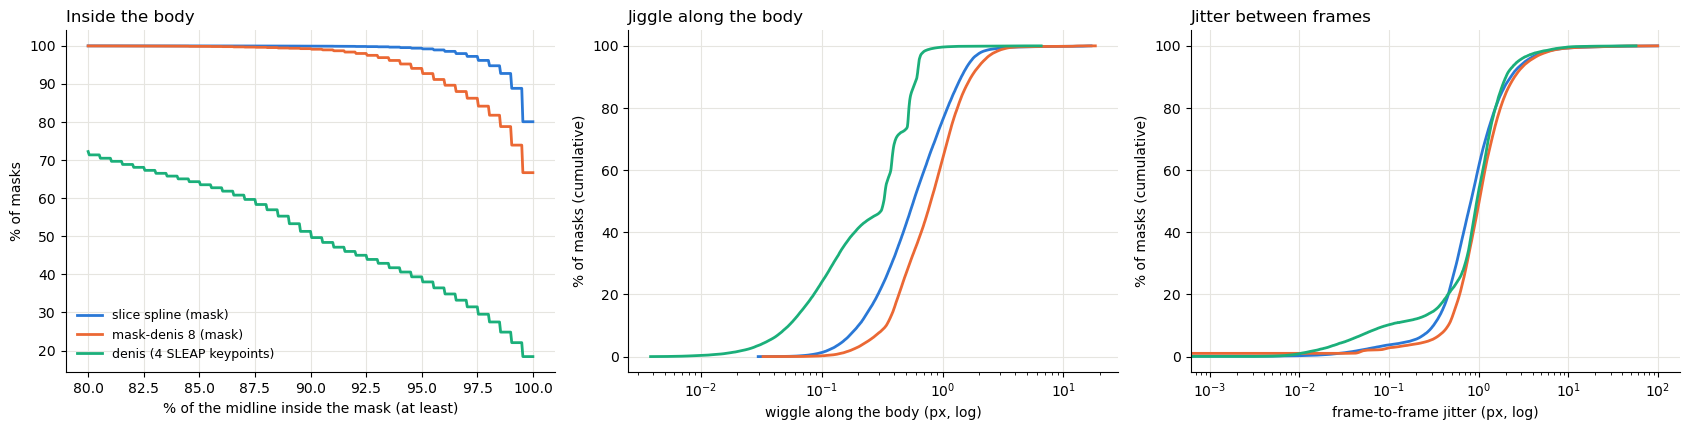

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
d3 = R[all3]
grid = np.linspace(80, 100, 401)
for k in AP:
    v = 100 * d3[f'{k}_inside'].values
    axs[0].plot(grid, [(v >= x).mean() * 100 for x in grid], color=COLOR[k], lw=2, label=NAME[k])
    w = np.sort(d3[f'{k}_wiggle'].values); axs[1].plot(w, np.arange(1, len(w) + 1) / len(w) * 100, color=COLOR[k], lw=2, label=NAME[k])
    j = np.sort(d3[f'{k}_jitter'].dropna().values); axs[2].plot(j, np.arange(1, len(j) + 1) / len(j) * 100, color=COLOR[k], lw=2, label=NAME[k])
axs[0].set_xlabel('% of the midline inside the mask (at least)'); axs[0].set_ylabel('% of masks'); axs[0].set_title('Inside the body', loc='left')
axs[1].set_xscale('log'); axs[1].set_xlabel('wiggle along the body (px, log)'); axs[1].set_ylabel('% of masks (cumulative)'); axs[1].set_title('Jiggle along the body', loc='left')
axs[2].set_xscale('log'); axs[2].set_xlabel('frame-to-frame jitter (px, log)'); axs[2].set_ylabel('% of masks (cumulative)'); axs[2].set_title('Jitter between frames', loc='left')
axs[0].legend(frameon=False, fontsize=9, loc='lower left')
plt.tight_layout(); plt.show()

## 4. Twenty frames per fish where the three disagree most

Among masks where all three midlines exist, ranked by the largest mean distance between any two of them; frames of the same
fish at least 50 frames apart, so a grid isn't one event twenty times. Grey = this fish's mask, darker grey = other fish.
Blue = slice spline, orange = mask-Denis 8 with its 8 points, aqua = Denis with the 4 SLEAP keypoints; filled circle = head end.
The title gives the largest mean distance and which two disagree. Every panel is also saved as a 300-dpi PNG in `FIG_DIR/fish<L>/`.

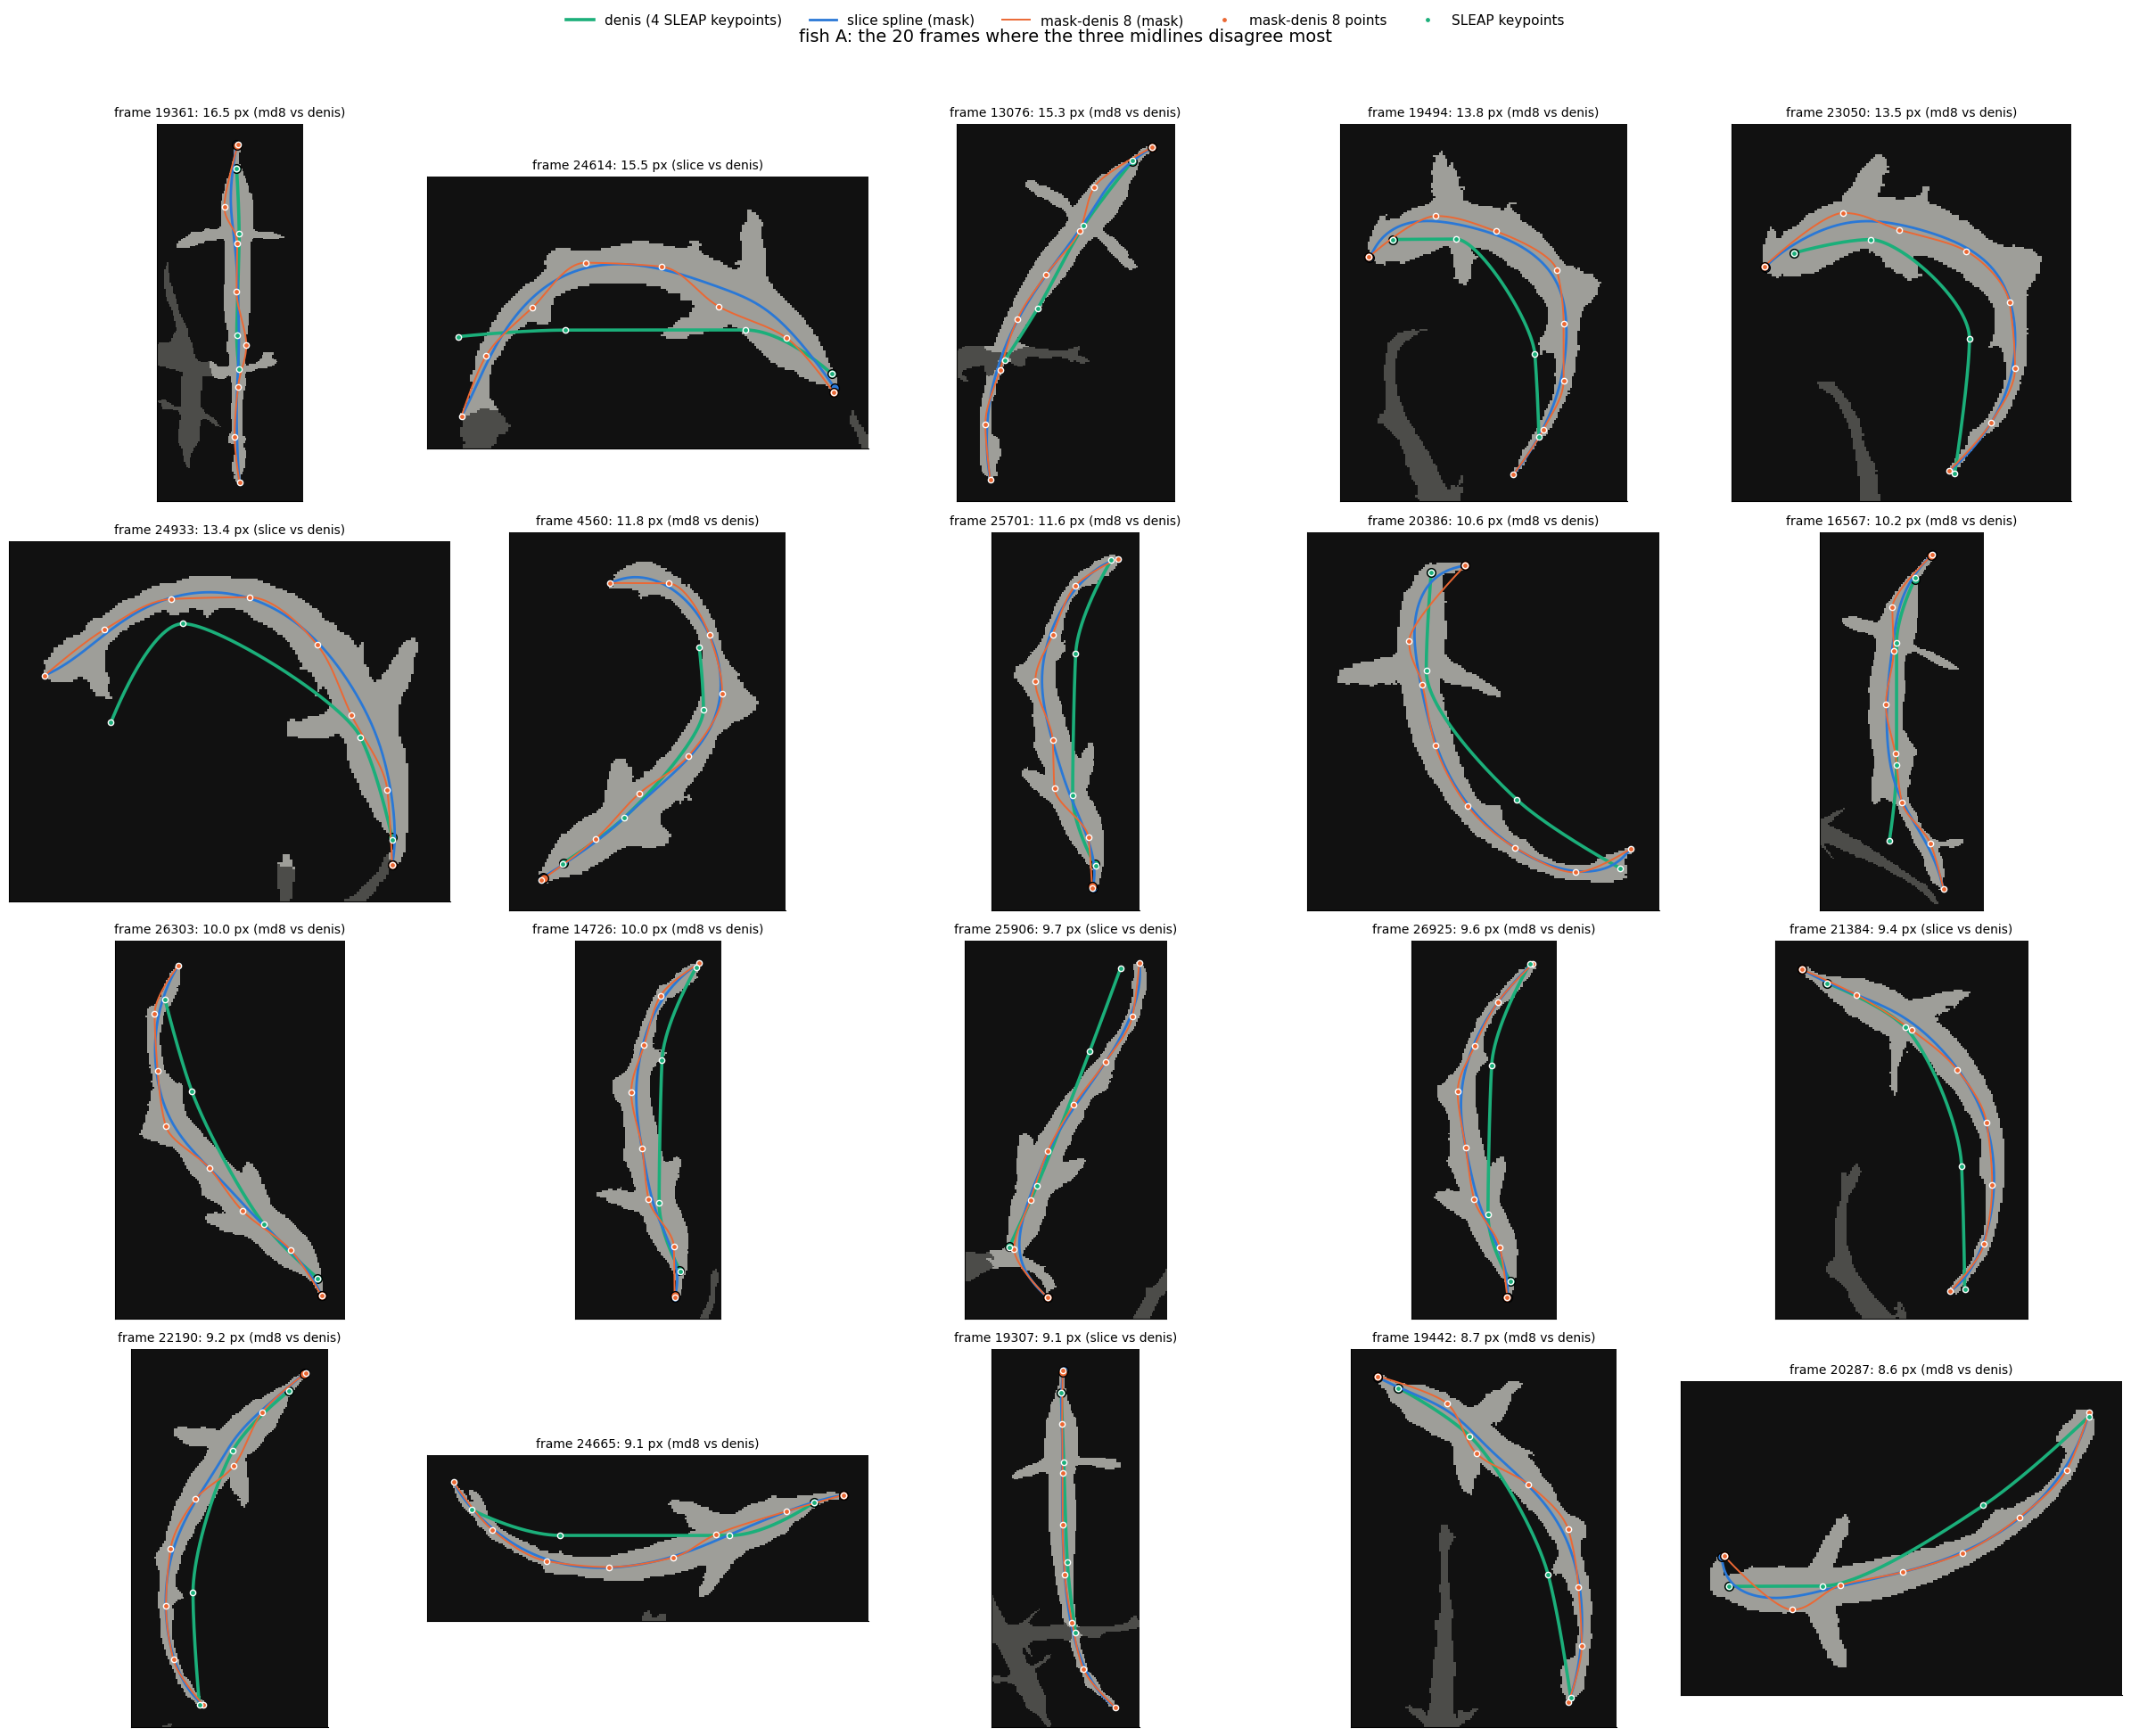

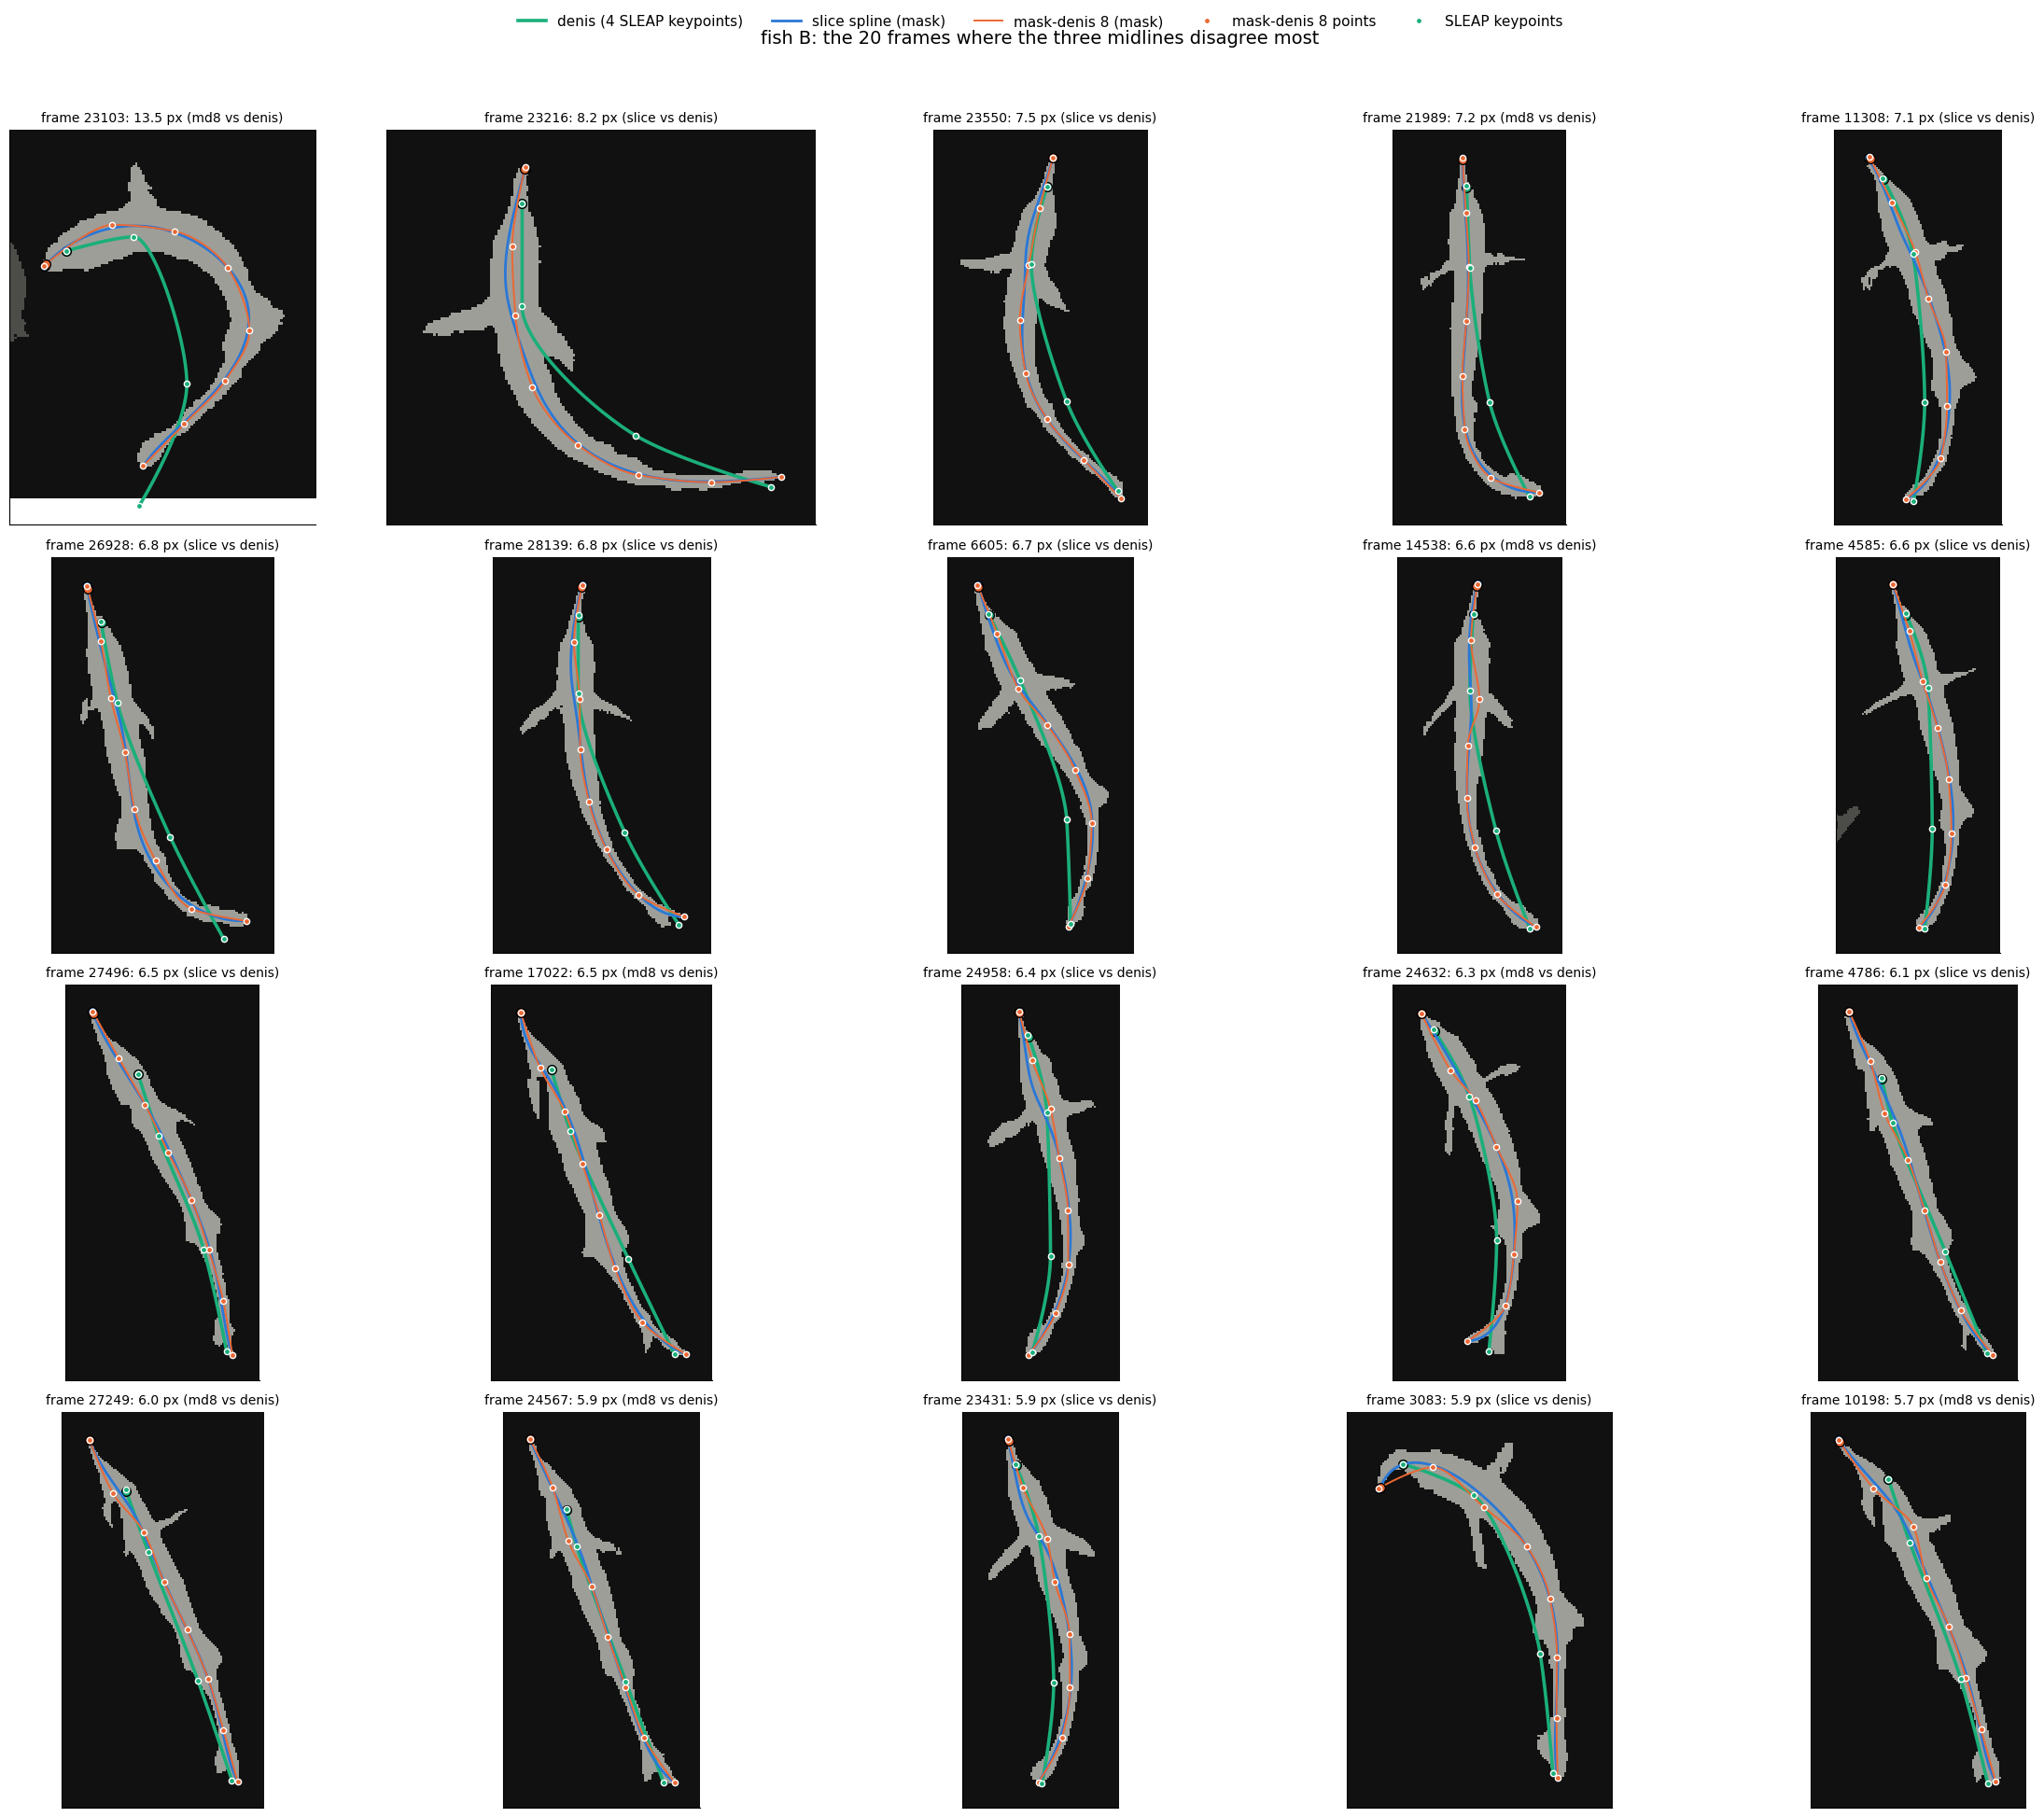

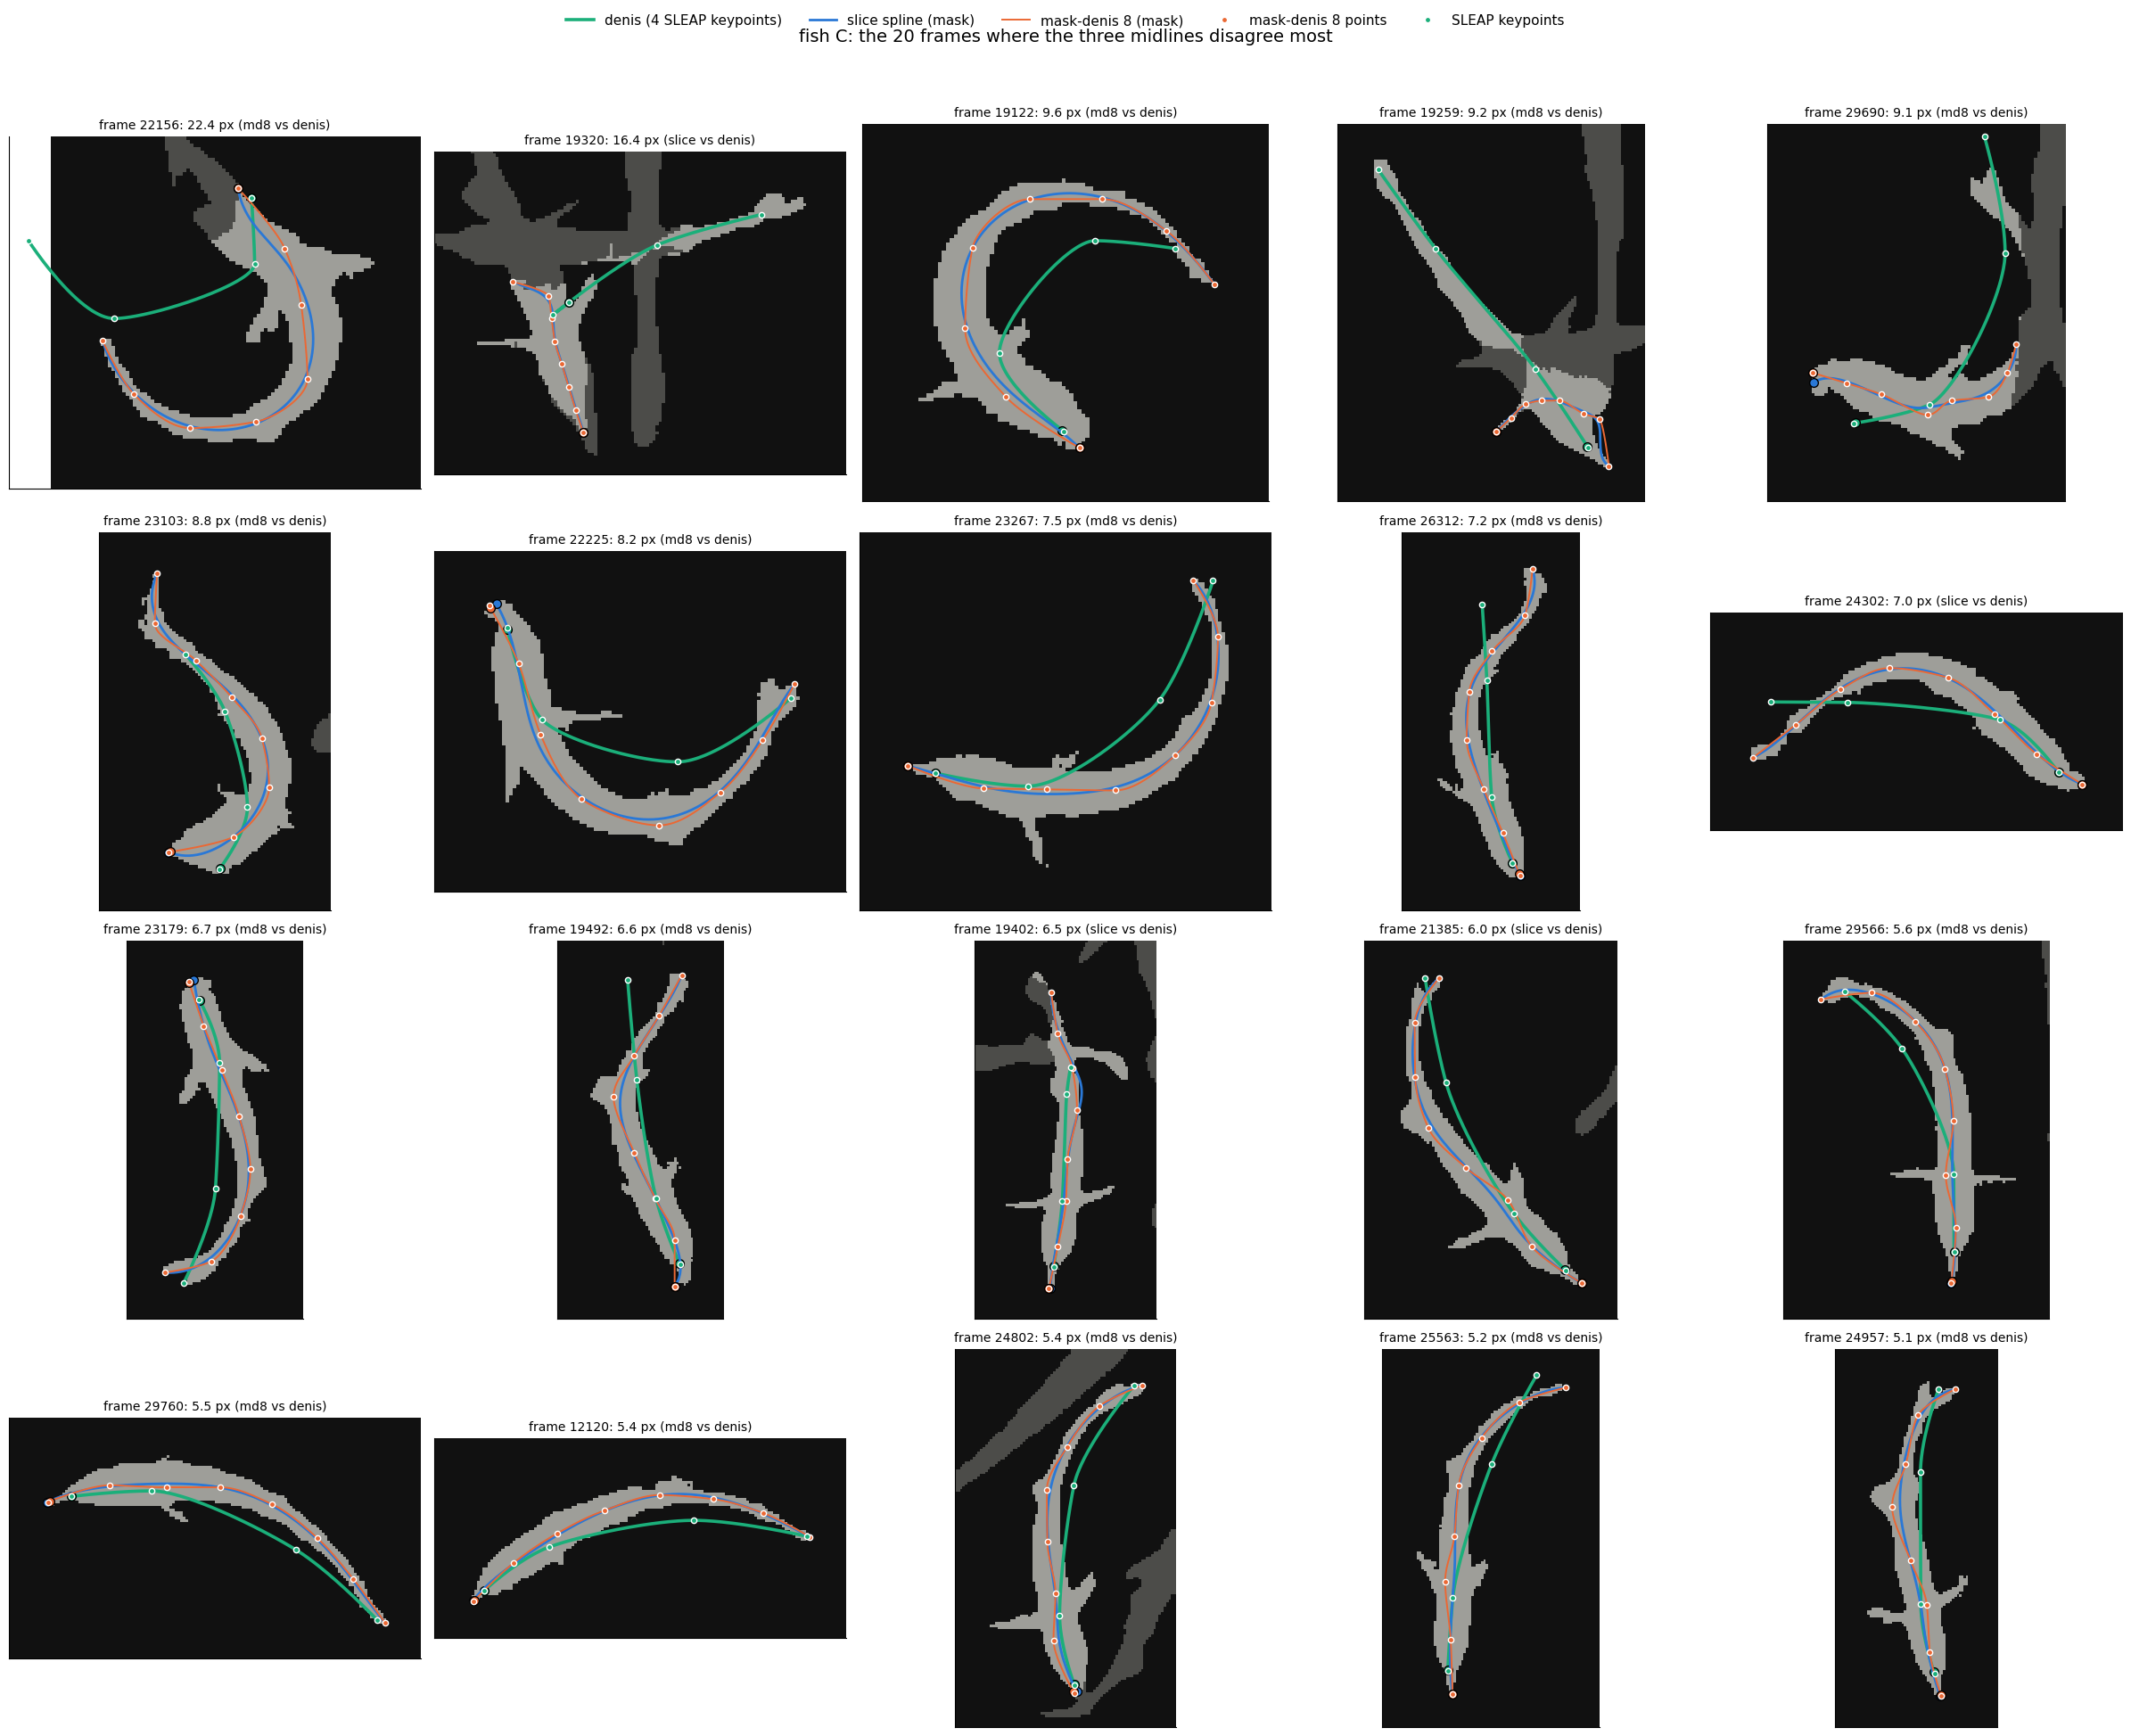

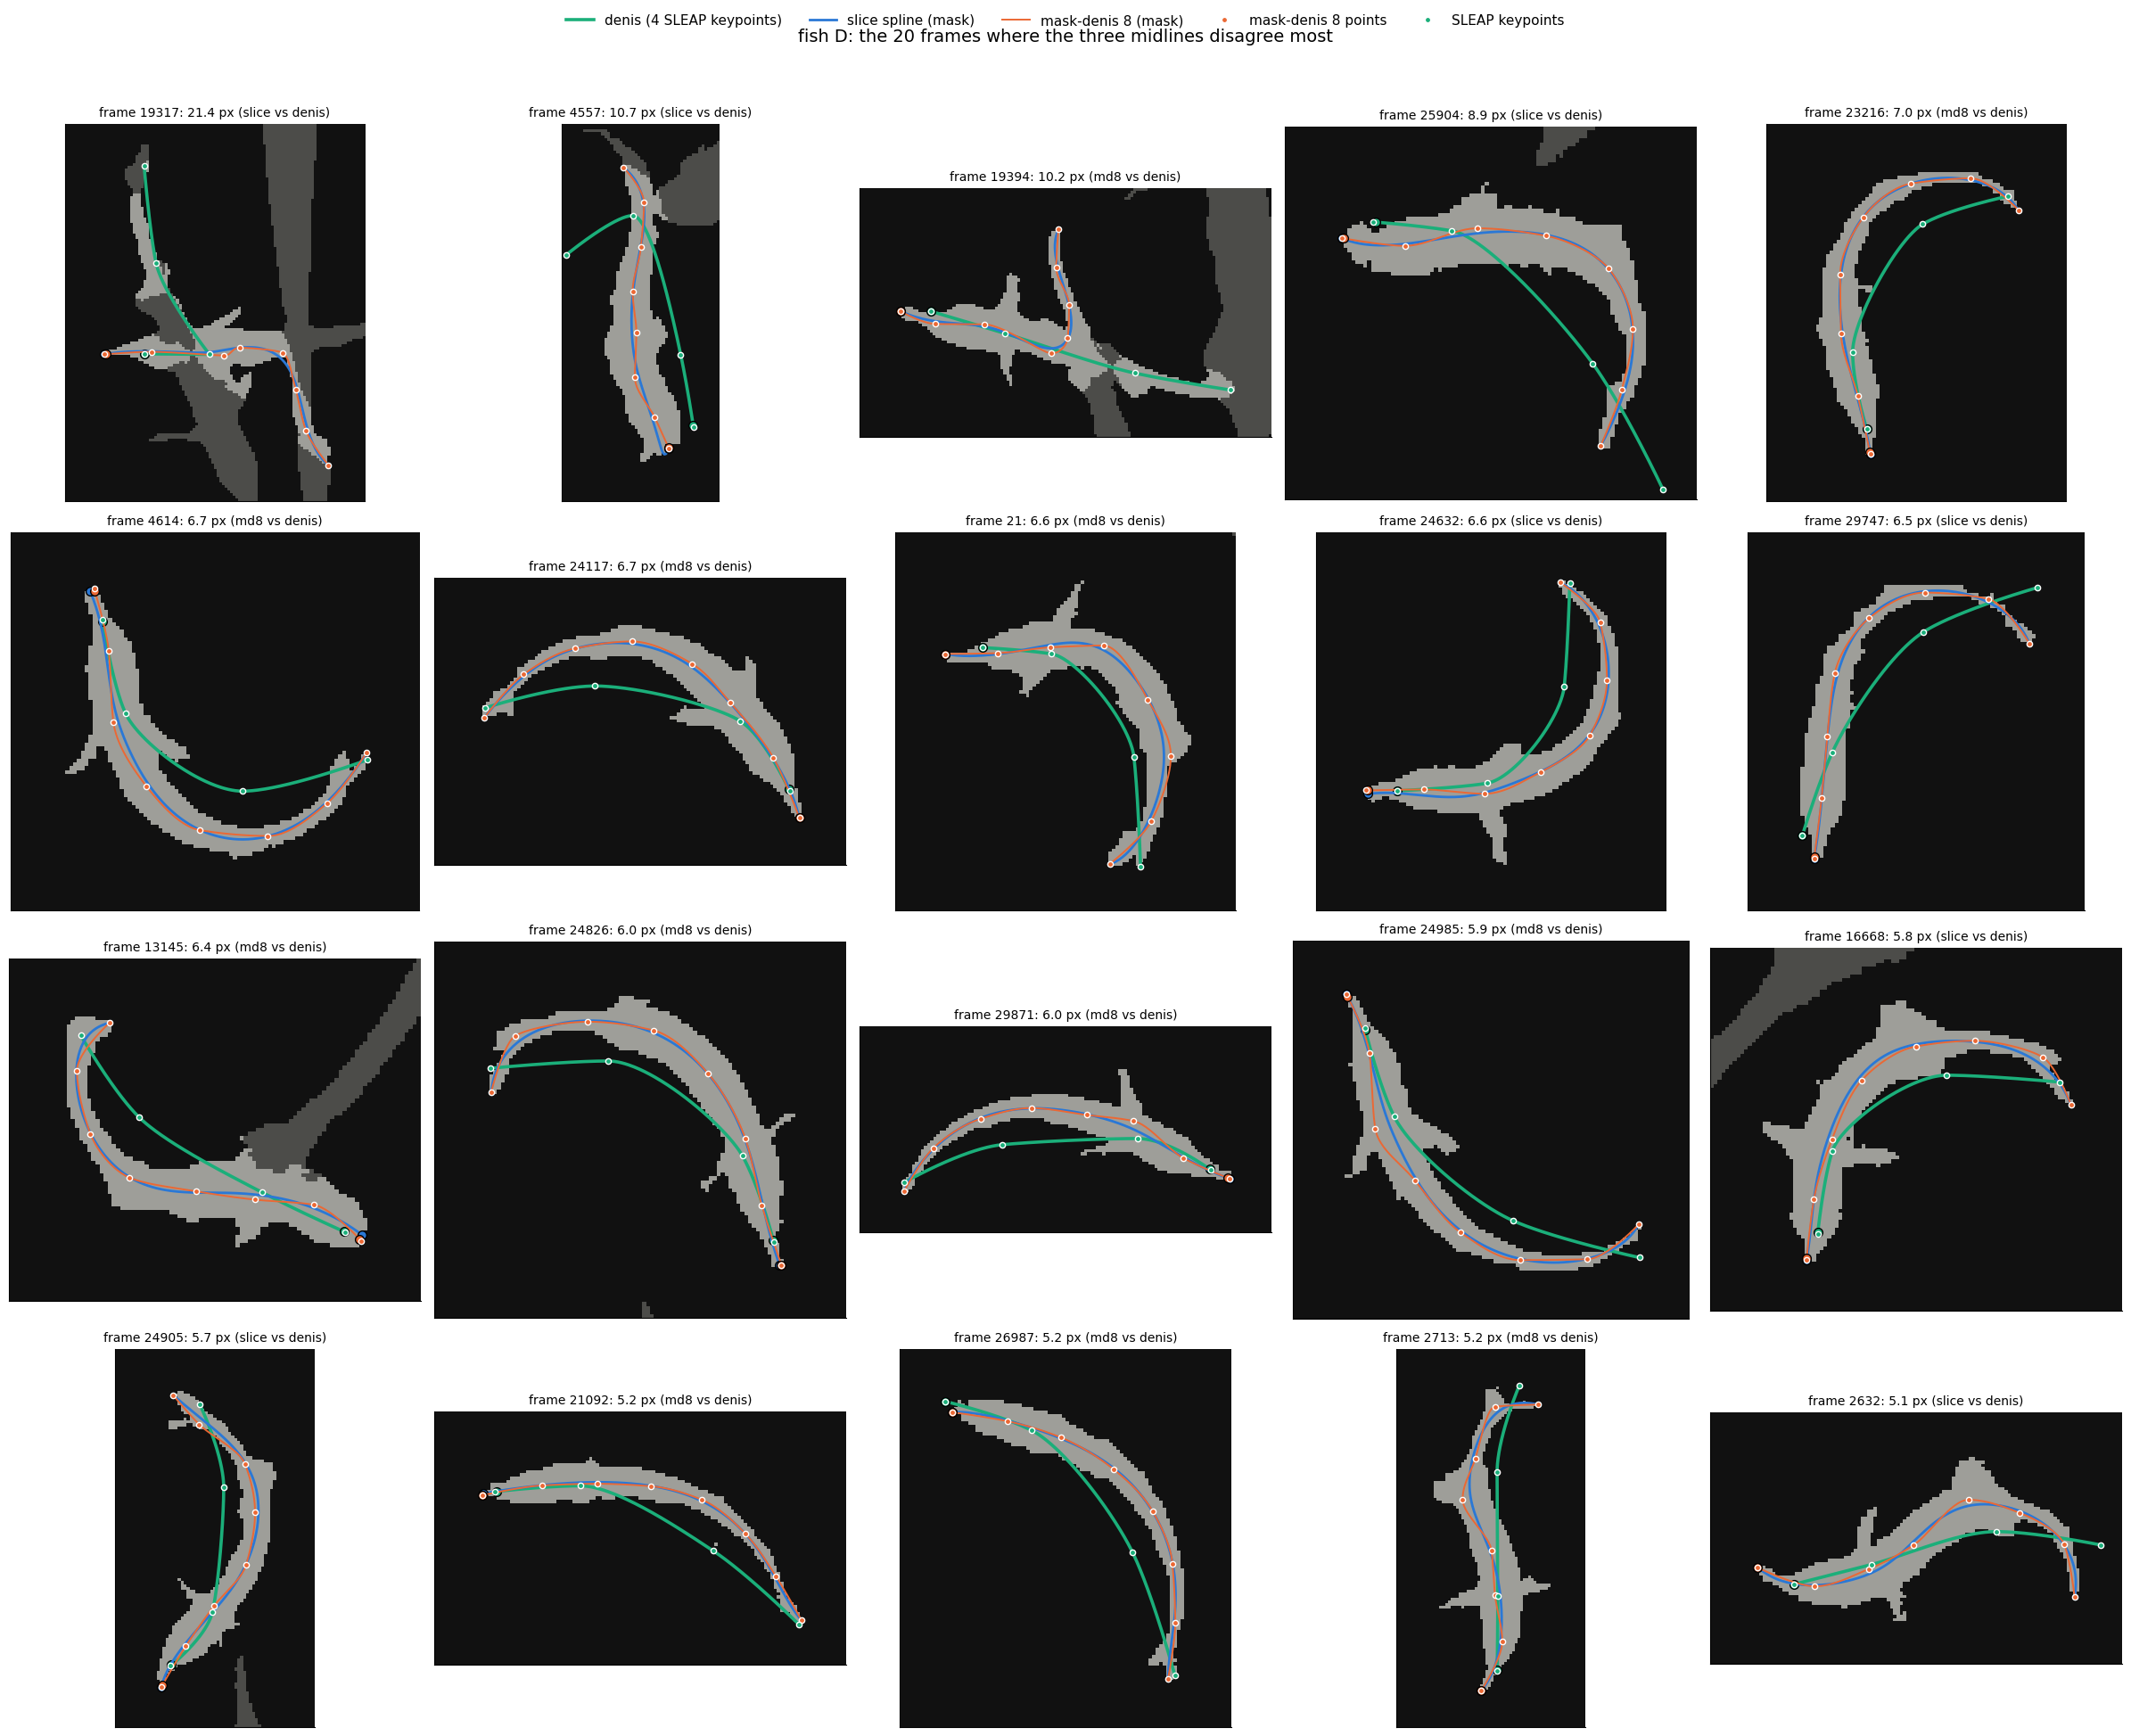

In [8]:
pair_cols = {f'd_{a}__{b}_mean': (a, b) for a, b in pairs}
D3 = R[all3].copy()
D3['disagreement'] = D3[list(pair_cols)].max(axis=1); D3['worst_pair'] = D3[list(pair_cols)].idxmax(axis=1).map(lambda c: pair_cols[c])

def pick(d, n=20, gap=50):
    chosen = []
    for _, r in d.sort_values('disagreement', ascending=False).iterrows():
        if all(abs(r.frame - f) >= gap for f in chosen): chosen.append(int(r.frame))
        if len(chosen) == n: break
    return chosen

def show(ax, F, L, pad=14):
    i = LETTERS.index(L); m = kaden_mask(F, i); kp = sleap_kp(F, L)
    cs, pts, info = fr.midlines(m, kp, CONT.get((F, L)))
    pix = np.argwhere(m); lo, hi = np.maximum(pix.min(0) - pad, 0), np.minimum(pix.max(0) + pad, P)
    img = np.ones((P, P, 3)) * 0.07
    for j in range(4):
        if j != i: img[kaden_mask(F, j)] = (0.30, 0.30, 0.29)
    img[m] = (0.62, 0.62, 0.60)
    ax.imshow(img[lo[0]:hi[0], lo[1]:hi[1]], extent=(lo[1] - .5, hi[1] - .5, hi[0] - .5, lo[0] - .5), interpolation='nearest')
    for k, lw in (('denis', 2.6), ('slice', 2.0), ('md8', 1.4)):
        c = cs[k]
        if c is None: continue
        ax.plot(c[:, 1], c[:, 0], color=COLOR[k], lw=lw, label=NAME[k]); ax.plot(c[-1, 1], c[-1, 0], 'o', color=COLOR[k], mec='k', ms=7)
    ax.plot(pts[:, 1], pts[:, 0], 'o', color=COLOR['md8'], mec='white', ms=4.5, label='mask-denis 8 points')
    ax.plot(kp[:, 1], kp[:, 0], 'o', color=COLOR['denis'], mec='white', ms=4.5, label='SLEAP keypoints')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

short = {'slice': 'slice', 'md8': 'md8', 'denis': 'denis'}
picks = {L: pick(D3[D3.fish == L]) for L in LETTERS}
for L in LETTERS:
    fig, axs = plt.subplots(4, 5, figsize=(24, 19.5))
    d = D3[D3.fish == L].set_index('frame')
    for ax, F in zip(axs.flat, picks[L]):
        show(ax, F, L); a, b = d.at[F, 'worst_pair']
        ax.set_title(f'frame {F}: {d.at[F, "disagreement"]:.1f} px ({short[a]} vs {short[b]})', fontsize=10)
    for ax in axs.flat[len(picks[L]):]: ax.axis('off')
    h, l = axs.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=5, fontsize=11, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f'fish {L}: the 20 frames where the three midlines disagree most', y=0.985, fontsize=14, x=0.5, ha='center')
    plt.tight_layout(rect=(0, 0, 1, 0.965)); plt.show()

In [9]:
n = 0
for L in LETTERS:
    out = f'{FIG_DIR}/fish{L}'; os.makedirs(out, exist_ok=True); d = D3[D3.fish == L].set_index('frame')
    for j, F in enumerate(picks[L], 1):
        fig, ax = plt.subplots(figsize=(10, 9)); show(ax, F, L, pad=18); ax.legend(fontsize=9, loc='best')
        a, b = d.at[F, 'worst_pair']
        ax.set_title(f'fish {L}, frame {F}: largest mean distance {d.at[F, "disagreement"]:.1f} px ({NAME[a]} vs {NAME[b]})', fontsize=10)
        fig.savefig(f'{out}/{j:02d}_frame{F}.png', dpi=300, bbox_inches='tight'); plt.close(fig); n += 1
print(f'saved {n} images to {FIG_DIR}/fish*/')
print('which pair disagrees most in the 80 frames:', pd.Series([NAME[a] + ' vs ' + NAME[b] for L in LETTERS for a, b in D3[D3.fish == L].set_index('frame').loc[picks[L], 'worst_pair']]).value_counts().to_dict())

saved 80 images to figures/midline_fitting_12_32_58/fish*/
which pair disagrees most in the 80 frames: {'mask-denis 8 (mask) vs denis (4 SLEAP keypoints)': 51, 'slice spline (mask) vs denis (4 SLEAP keypoints)': 29}
